# UMAP of DS PMC Corpus by OpenAlex Topic

Fits UMAP on all 65,677 vectors (1,594 original research articles; article-only corpus since the 2026-09-06 purge) from `DS_INCLUDE_2026_09_02_DEEPINFRA_2048` and saves 5 figures (Topic, Topic incl. rank-1 DS, Subfield, Section, INCLUDE) plus standalone legends and a coordinates CSV to `analysis/output/ScientificReportRevisionV1/umap_topic/`.

Topic colours are harmonized with notebook 2's `topic_distribution_bar_top10` barplot (NPG10 palette): Figure A colours ranks 2-11 (rank-1 DS topic grouped as gray "Other"); Figure A2 (`umap_corpus_topic_incl_ds`) colours the barplot's exact top-10 including the rank-1 DS topic in navy.


## Cell 1 — Config

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv

# ── Paths ─────────────────────────────────────────────────────────────────────
_NB_DIR  = Path('..').resolve()          # analysis/
load_dotenv(_NB_DIR / '.env')            # analysis/.env → srv/.env symlink

# Scientific Reports revision (v1) — kept separate from the original submission's
# output/umap_topic/ results. This notebook has no dependency on the question
# benchmark (pure corpus/Milvus), so it re-runs identically regardless of the
# revised question set — the point of re-running it is the palette/labeling fixes
# below, not new input data.
OUTPUT_DIR = _NB_DIR / 'output' / 'ScientificReportRevisionV1' / 'umap_topic'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Milvus ────────────────────────────────────────────────────────────────────
EXPECTED_COLLECTION = 'DS_INCLUDE_2026_09_02_DEEPINFRA_2048'   # live corpus, articles only since 2026-09-06 purge (65,677 vectors)
COLLECTION_NAME = os.getenv('MILVUS_COLLECTION', EXPECTED_COLLECTION)
assert COLLECTION_NAME == EXPECTED_COLLECTION, (
    f'MILVUS_COLLECTION resolved to {COLLECTION_NAME!r}, expected {EXPECTED_COLLECTION!r} — '
    'srv/.env has drifted; update EXPECTED_COLLECTION here if this is intentional.'
)
MILVUS_URI      = os.getenv('MILVUS_URI', 'http://localhost:19530')

# ── UMAP ──────────────────────────────────────────────────────────────────────
UMAP_SEED    = 42
N_NEIGHBORS  = 15
MIN_DIST     = 0.1

# ── Plot ──────────────────────────────────────────────────────────────────────
TOP_TOPICS    = 10    # top N topics to colour individually (ranks 2–11, skipping rank 1)
TOP_SUBFIELDS = 10    # top N subfields to colour individually (ranks 2–11, skipping rank 1)
PT_SIZE       = 5     # scatter point size  (matches notebook 6)
PT_ALPHA      = 0.40  # scatter alpha     (matches notebook 6)
DPI           = 150   # display DPI
SAVE_DPI      = 600   # save DPI (publication quality)

print(f'Milvus URI  : {MILVUS_URI}')
print(f'Collection  : {COLLECTION_NAME}')
print(f'Output dir  : {OUTPUT_DIR}')

Milvus URI  : http://localhost:19530
Collection  : DS_INCLUDE_2026_09_02_DEEPINFRA_2048
Output dir  : /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic


## Cell 2 — Imports

In [2]:
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import umap
from tqdm.auto import tqdm
from pymilvus import connections, Collection

# ── Publication-quality rcParams ─────────────────────────────────────────────
mpl.rcParams.update({
    'font.family'          : 'sans-serif',
    'font.sans-serif'      : ['Arial', 'Helvetica Neue', 'Helvetica', 'DejaVu Sans'],
    'font.size'            : 18,
    'axes.titlesize'       : 20,
    'axes.titleweight'     : 'bold',
    'axes.labelsize'       : 20,
    'axes.labelweight'     : 'bold',
    'xtick.labelsize'      : 17,
    'ytick.labelsize'      : 17,
    'legend.fontsize'      : 16,
    'legend.title_fontsize': 18,
    'legend.framealpha'    : 0.95,
    'legend.edgecolor'     : '#CCCCCC',
    'legend.borderpad'     : 0.6,
    'axes.linewidth'       : 1.8,
    'xtick.major.width'    : 1.8,
    'ytick.major.width'    : 1.8,
    'xtick.major.size'     : 5.0,
    'ytick.major.size'     : 5.0,
    'axes.spines.top'      : False,
    'axes.spines.right'    : False,
    'figure.facecolor'     : 'white',
    'axes.facecolor'       : 'white',
    'grid.color'           : '#E5E5E5',
    'grid.linewidth'       : 0.5,
    'grid.linestyle'       : '--',
    'pdf.fonttype'         : 42,
    'ps.fonttype'          : 42,
    'figure.dpi'           : 150,
    'savefig.dpi'          : 600,
})

print('Imports OK')

/home/user/anaconda3/envs/dschat/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports OK


## Cell 3 — Connect to Milvus & Fetch Metadata (cursor-based)

In [3]:
connections.connect(uri=MILVUS_URI)
collection = Collection(COLLECTION_NAME)
collection.load()
print(f'Collection : {COLLECTION_NAME}')
print(f'Vectors    : {collection.num_entities:,}')

# ── Cursor-based pagination — fetch metadata (no vectors yet) ─────────────────
_PAGE         = 16_000
_META_FIELDS  = ['pk', 'pmcid', 'section', 'topic', 'subfield', 'pub_field',
                 'domain', 'is_include']

_meta_rows, _last_pk = [], -1
print('\nFetching metadata …')
with tqdm(total=collection.num_entities, unit='rows') as _pbar:
    while True:
        _page = collection.query(
            expr=f'pk > {_last_pk}',
            output_fields=_META_FIELDS,
            limit=_PAGE,
        )
        if not _page:
            break
        _meta_rows.extend(_page)
        _last_pk = max(r['pk'] for r in _page)
        _pbar.update(len(_page))
        if len(_page) < _PAGE:
            break

df_meta = pd.DataFrame(_meta_rows)
print(f'\nRows fetched    : {len(df_meta):,}')
print(f'Unique topics   : {df_meta["topic"].nunique():,}')
print(f'Unique subfields: {df_meta["subfield"].nunique():,}')
print(f'Sections        : {dict(Counter(df_meta["section"]))}')
print(f'INCLUDE rows    : {(df_meta["is_include"]==1).sum():,}')

Collection : DS_INCLUDE_2026_09_02_DEEPINFRA_2048
Vectors    : 65,677

Fetching metadata …


  0%|          | 0/65677 [00:00<?, ?rows/s]

100%|██████████| 65677/65677 [00:00<00:00, 189850.39rows/s]



Rows fetched    : 65,677
Unique topics   : 219
Unique subfields: 73
Sections        : {'Methods': 16811, 'Discussion': 16268, 'Results': 19886, 'Introduction': 7932, 'Conclusion': 1281, 'Abstract': 3499}
INCLUDE rows    : 7,990


## Cell 4 — Fetch All Embedding Vectors (batches of 100)

In [4]:
_BATCH = 100
all_pks = df_meta['pk'].tolist()

print(f'Fetching {len(all_pks):,} vectors in batches of {_BATCH} …')
pk2vec: dict = {}

for _i in tqdm(range(0, len(all_pks), _BATCH), unit='batch'):
    _batch = all_pks[_i : _i + _BATCH]
    for _r in collection.query(
        expr=f'pk in {_batch}',
        output_fields=['pk', 'vector'],
    ):
        pk2vec[_r['pk']] = np.array(_r['vector'], dtype=np.float32)

# Align: keep only rows where we got a vector
mask   = df_meta['pk'].isin(pk2vec)
df_ok  = df_meta[mask].reset_index(drop=True)
bg_embs = np.array([pk2vec[pk] for pk in df_ok['pk']], dtype=np.float32)

print(f'Vectors aligned : {len(bg_embs):,}  shape={bg_embs.shape}')

Fetching 65,677 vectors in batches of 100 …


100%|██████████| 657/657 [00:11<00:00, 57.46batch/s]


Vectors aligned : 65,677  shape=(65677, 2048)


## Cell 5 — Fit UMAP

In [5]:
print(f'Fitting UMAP  (n_neighbors={N_NEIGHBORS}, min_dist={MIN_DIST}, metric=cosine, seed={UMAP_SEED}) …')
print('This takes ~5–10 min for 66K × 2048-dim vectors on CPU.')

reducer = umap.UMAP(
    n_neighbors  = N_NEIGHBORS,
    min_dist     = MIN_DIST,
    n_components = 2,
    metric       = 'cosine',
    random_state = UMAP_SEED,
    low_memory   = True,
)
bg_2d = reducer.fit_transform(bg_embs)

df_ok = df_ok.copy()
df_ok['umap_x'] = bg_2d[:, 0]
df_ok['umap_y'] = bg_2d[:, 1]

print(f'UMAP done — shape: {bg_2d.shape}')

Fitting UMAP  (n_neighbors=15, min_dist=0.1, metric=cosine, seed=42) …
This takes ~5–10 min for 66K × 2048-dim vectors on CPU.


/home/user/anaconda3/envs/dschat/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/user/anaconda3/envs/dschat/lib/python3.11/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


UMAP done — shape: (65677, 2)


## Cell 6 — Helpers: build_color_map · scatter_umap · _save_fig

In [6]:
# 25-colour qualitative palette (tab20 + 5 extras)
_TAB20 = plt.cm.tab20.colors                              # 20 colours
_EXTRA = ['#e377c2', '#bcbd22', '#17becf', '#9467bd', '#8c564b']  # 5 more
_Q25   = list(_TAB20) + _EXTRA

def build_color_map(series: pd.Series, top_n: int, other_label: str = 'Other', skip_top: int = 1):
    """
    Return (series_with_labels_clipped, color_dict).
    Skips the top `skip_top` most common values (e.g. skip rank 1 which is the dominant
    DS category), then colours the next `top_n` values; the rest become `other_label` (gray).
    """
    counts  = Counter(series.dropna().astype(str).tolist())
    all_top = [t for t, _ in counts.most_common(top_n + skip_top) if t not in ('', 'nan', 'None')]
    top     = all_top[skip_top : skip_top + top_n]   # ranks 2 … top_n+1
    cmap    = {t: _Q25[i % len(_Q25)] for i, t in enumerate(top)}
    cmap[other_label] = '#CCCCCC'

    clipped = series.astype(str).apply(
        lambda v: v if v in cmap and v not in ('', 'nan', 'None') else other_label
    )
    return clipped, cmap


def scatter_umap(ax, df, color_col, cmap, title, pt_size=PT_SIZE, pt_alpha=PT_ALPHA,
                 other_label='Other'):
    """
    Plot UMAP scatter without a legend (legend is saved as a separate figure).
    Returns list of Patch handles for _save_legend_fig.
    """
    # Draw 'Other' first so named groups render on top
    _other = df[df[color_col] == other_label]
    ax.scatter(
        _other['umap_x'], _other['umap_y'],
        c=cmap[other_label], s=pt_size, alpha=pt_alpha * 0.6,
        linewidths=0, rasterized=False,
    )
    # Named groups
    named_labels = [k for k in cmap if k != other_label]
    for label in named_labels:
        _sub = df[df[color_col] == label]
        if len(_sub) == 0:
            continue
        ax.scatter(
            _sub['umap_x'], _sub['umap_y'],
            c=cmap[label], s=pt_size, alpha=pt_alpha,
            linewidths=0, rasterized=False,
        )
    ax.set_xlabel('UMAP 1', labelpad=4)
    ax.set_ylabel('UMAP 2', labelpad=4)
    return [mpatches.Patch(color=cmap[lbl], label=lbl)
            for lbl in named_labels + [other_label]]


def _save_legend_fig(handles, title, stem, ncol=2):
    """Save legend as a standalone PDF/JPEG/TIFF (no axes, no scatter)."""
    n_rows = (len(handles) + ncol - 1) // ncol
    fig_h  = max(0.6, n_rows * 0.48 + 0.65)
    fig_w  = min(ncol * 3.2, 9.0)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis('off')
    ax.legend(
        handles=handles, title=title,
        loc='center',
        ncol=ncol, framealpha=0.92, edgecolor='#BBBBBB',
        markerscale=2.2, borderpad=0.6,
    )
    fig.tight_layout()
    _save_fig(fig, stem + '_legend')
    plt.close(fig)


def _save_fig(fig, stem: str) -> None:
    """Save figure as PDF, JPEG, and TIFF at 600 dpi — matches notebook 6."""
    for fmt, ext in [('pdf', 'pdf'), ('jpeg', 'jpg'), ('tiff', 'tiff')]:
        fig.savefig(
            OUTPUT_DIR / f'{stem}.{ext}',
            dpi=SAVE_DPI, bbox_inches='tight', format=fmt, facecolor='white',
        )

print('Helpers defined.')

Helpers defined.


## Cell 7 — Figure A: Corpus by OpenAlex Topic

/tmp/ipykernel_1210475/3522043183.py:67: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


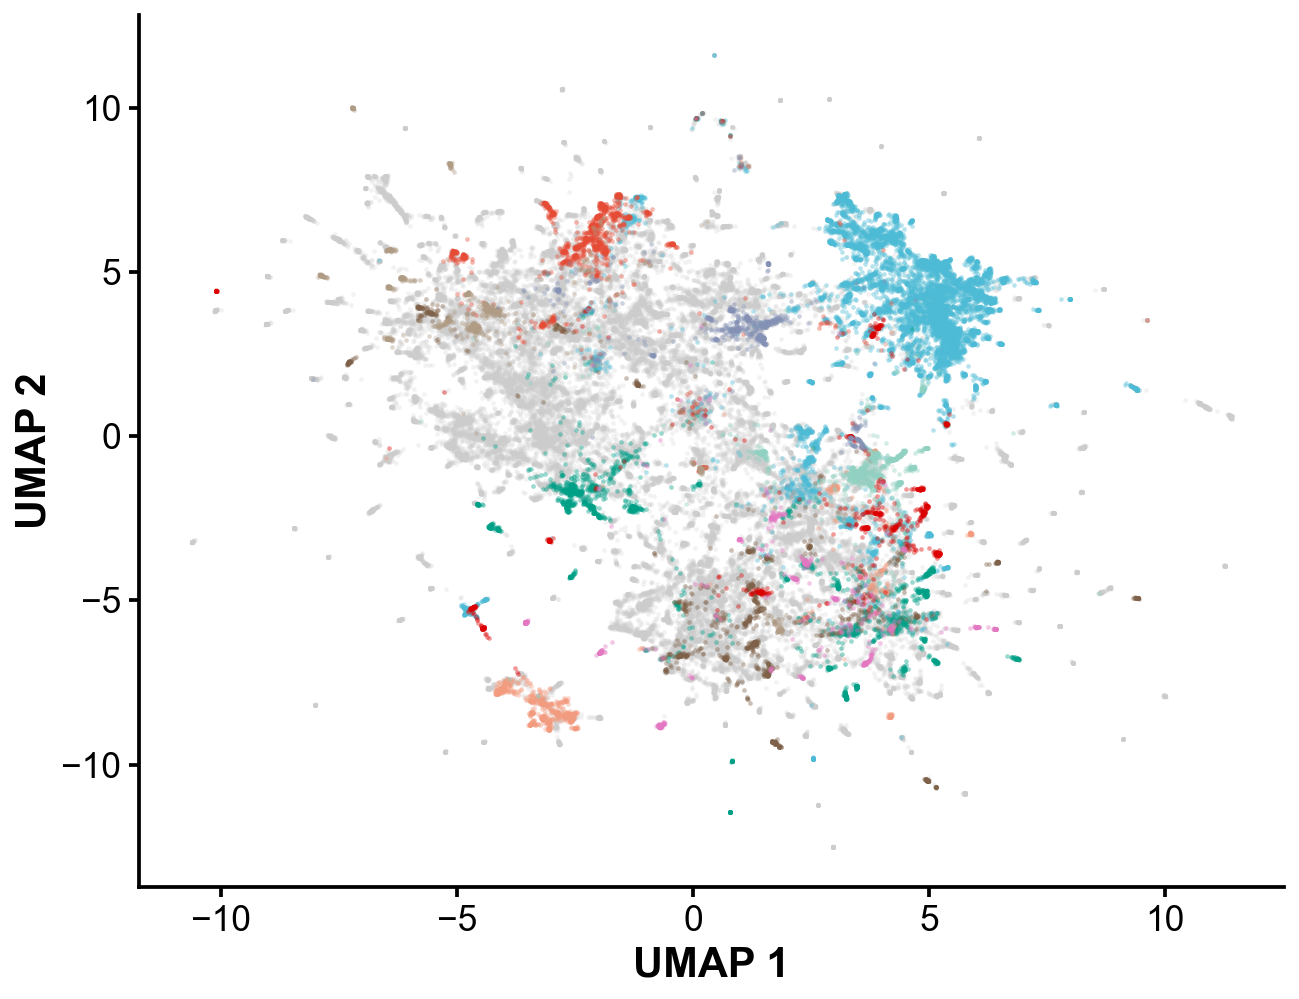

Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_topic.{pdf,jpg,tiff}
Legend → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_topic_legend.{pdf,jpg,tiff}

Total unique topics in corpus : 219
Top 10 topics by chunk count (shown individually in Figure A):
                                             topic  n_chunks  pct
Down syndrome and intellectual disability research     28670 43.7
                Prenatal Screening and Diagnostics      8565 13.0
       Alzheimer's disease research and treatments      2035  3.1
            Family and Disability Support Research      1275  1.9
         Genetics and Neurodevelopmental Disorders      1190  1.8
                   Acute Myeloid Leukemia Research      1090  1.7
                   Epigenetics and DNA Methylation       971  1.5
                 Autism Spectrum Disorder Research       931  1.4
  Genomic variations a

In [7]:
df_ok['topic_clean'] = df_ok['topic'].fillna('').astype(str).str.strip()
topic_col, topic_cmap = build_color_map(df_ok['topic_clean'], TOP_TOPICS)

# ── Colour harmonization with notebook 2's topic-distribution barplot ─────────
# 2_publication_metadata_analysis.ipynb ("topic_distribution_bar_top10") colours
# the top-10 topics by ARTICLE count with the NPG10 palette in rank order. The
# exact topic → colour pairs are replicated here so every topic keeps a single
# colour across both figures. The rank-1 DS topic (#3C5488 in the barplot) stays
# grouped as gray "Other" in this UMAP by design (skip_top=1); topics coloured
# here but absent from the barplot's top-10 (e.g. chunk-rank 11, "Signaling
# Pathways in Disease") get fallback colours from outside the NPG set.
NPG10 = ["#3C5488", "#4DBBD5", "#00A087", "#E64B35",
         "#F39B7F", "#8491B4", "#91D1C2", "#7E6148",
         "#B09C85", "#DC0000"]
TOPIC_BARPLOT_CMAP = {   # notebook 2 barplot order: article count desc
    'Down syndrome and intellectual disability research': NPG10[0],
    'Prenatal Screening and Diagnostics':                 NPG10[1],
    "Alzheimer's disease research and treatments":        NPG10[2],
    'Family and Disability Support Research':             NPG10[3],
    'Acute Myeloid Leukemia Research':                    NPG10[4],
    'Congenital Heart Disease Studies':                   NPG10[5],
    'Epigenetics and DNA Methylation':                    NPG10[6],
    'Genetics and Neurodevelopmental Disorders':          NPG10[7],
    'Autism Spectrum Disorder Research':                  NPG10[8],
    'Genomic variations and chromosomal abnormalities':   NPG10[9],
}
# Sanity check: fail loudly if the corpus's top-10 topics by article count no
# longer match the barplot mapping (tie order aside) — update both notebooks then.
_top10_by_article = set(
    df_ok.drop_duplicates('pmcid')['topic_clean'].value_counts().head(10).index
)
assert _top10_by_article == set(TOPIC_BARPLOT_CMAP), (
    "Top-10 topics by article count drifted from notebook 2's barplot mapping — "
    f"update TOPIC_BARPLOT_CMAP. Diff: {_top10_by_article ^ set(TOPIC_BARPLOT_CMAP)}"
)
_NPG_FALLBACK = iter(['#E377C2', '#BCBD22', '#17BECF', '#9467BD', '#8C564B'])
for _t in list(topic_cmap):
    if _t == 'Other':
        continue
    if _t in TOPIC_BARPLOT_CMAP:
        topic_cmap[_t] = TOPIC_BARPLOT_CMAP[_t]
    else:
        topic_cmap[_t] = next(_NPG_FALLBACK)

df_ok['topic_col'] = topic_col

_n_unique_topics = df_ok['topic_clean'].nunique()

_title_topic = f'OpenAlex Topic  (top {TOP_TOPICS} of {_n_unique_topics} shown)'
fig, ax = plt.subplots(figsize=(9, 7))
handles = scatter_umap(ax, df_ok, 'topic_col', topic_cmap, title=_title_topic)
plt.tight_layout()
_save_fig(fig, 'umap_corpus_topic')
_save_legend_fig(handles, _title_topic, 'umap_corpus_topic', ncol=2)
plt.show()
print(f'Saved → {OUTPUT_DIR}/umap_corpus_topic.{{pdf,jpg,tiff}}')
print(f'Legend → {OUTPUT_DIR}/umap_corpus_topic_legend.{{pdf,jpg,tiff}}')

# ── Topic frequency summary ───────────────────────────────────────────────────
# NOTE for the manuscript (reviewer feedback): this corpus contains
# `_n_unique_topics` distinct OpenAlex topics in total. Only the top TOP_TOPICS
# (ranks 2–TOP_TOPICS+1, skipping the dominant rank-1 category) are individually
# colored/named in Figure A and its legend — the remainder are grouped as "Other"
# (gray). Any caption or supplementary text reporting a topic count should match
# ONE of these two numbers explicitly (total vs. top-N shown) and should not
# describe the figure as containing "full topic assignments" — it shows only the
# top N by design.
print(f'\nTotal unique topics in corpus : {_n_unique_topics}')
print(f'Top {TOP_TOPICS} topics by chunk count (shown individually in Figure A):')
print(
    df_ok['topic_clean']
    .value_counts()
    .head(TOP_TOPICS)
    .rename_axis('topic')
    .reset_index(name='n_chunks')
    .assign(pct=lambda d: (d['n_chunks'] / len(df_ok) * 100).round(1))
    .to_string(index=False)
)

## Cell 7b — Figure A2: Barplot Top-10 Topics (including rank-1 DS topic)

/tmp/ipykernel_1210475/3522043183.py:67: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


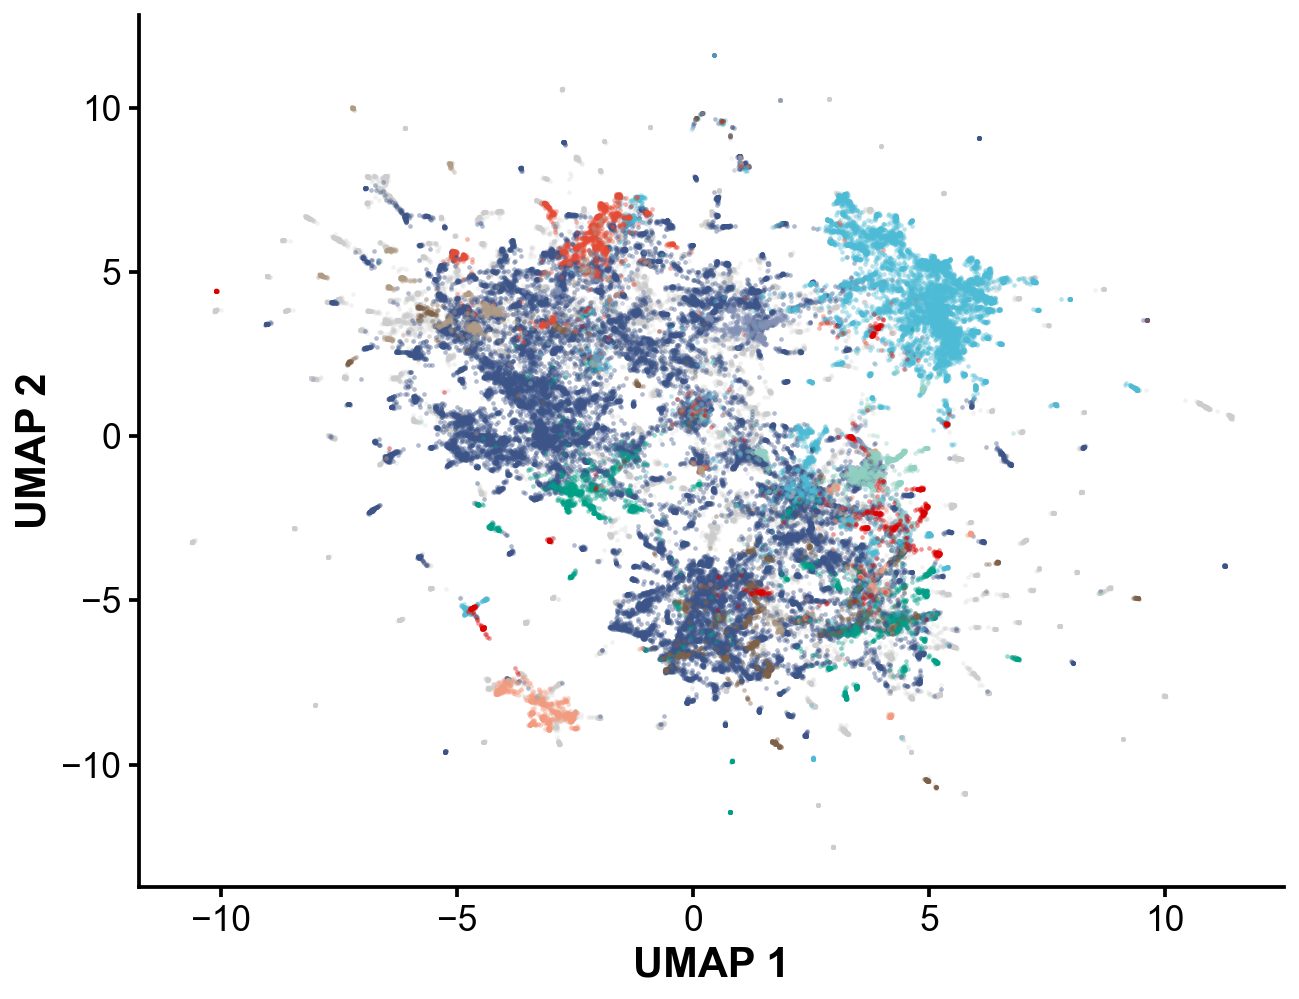

Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_topic_incl_ds.{pdf,jpg,tiff}
Legend → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_topic_incl_ds_legend.{pdf,jpg,tiff}

Chunk counts per coloured topic (Figure A2):
                                             topic  n_chunks
Down syndrome and intellectual disability research     28670
                Prenatal Screening and Diagnostics      8565
       Alzheimer's disease research and treatments      2035
            Family and Disability Support Research      1275
         Genetics and Neurodevelopmental Disorders      1190
                   Acute Myeloid Leukemia Research      1090
                   Epigenetics and DNA Methylation       971
                 Autism Spectrum Disorder Research       931
  Genomic variations and chromosomal abnormalities       775
                  Congenital Heart Disease S

In [8]:
# Figure A2 — the EXACT 10 topics from notebook 2's topic_distribution_bar_top10
# barplot, in the SAME NPG10 colours, INCLUDING the rank-1 "Down syndrome and
# intellectual disability research" topic (navy #3C5488) that Figure A deliberately
# grays out. Every topic outside the barplot's top-10 is gray "Other" — so this
# figure and the barplot share a single topic → colour mapping with no exceptions.
# Requires TOPIC_BARPLOT_CMAP and df_ok['topic_clean'] from Cell 7.
topic_cmap_bar10 = dict(TOPIC_BARPLOT_CMAP)
topic_cmap_bar10['Other'] = '#CCCCCC'
df_ok['topic_col_bar10'] = df_ok['topic_clean'].apply(
    lambda v: v if v in TOPIC_BARPLOT_CMAP else 'Other'
)

# scatter_umap draws named groups in dict order: the dominant DS topic (first key,
# 40.9% of articles) is painted first so the 9 smaller topics stay visible on top.
_title_bar10 = f'OpenAlex Topic  (barplot top 10 of {_n_unique_topics} shown)'
fig, ax = plt.subplots(figsize=(9, 7))
handles = scatter_umap(ax, df_ok, 'topic_col_bar10', topic_cmap_bar10, title=_title_bar10)
plt.tight_layout()
_save_fig(fig, 'umap_corpus_topic_incl_ds')
_save_legend_fig(handles, _title_bar10, 'umap_corpus_topic_incl_ds', ncol=2)
plt.show()
print(f'Saved → {OUTPUT_DIR}/umap_corpus_topic_incl_ds.{{pdf,jpg,tiff}}')
print(f'Legend → {OUTPUT_DIR}/umap_corpus_topic_incl_ds_legend.{{pdf,jpg,tiff}}')

print('\nChunk counts per coloured topic (Figure A2):')
print(
    df_ok.loc[df_ok['topic_col_bar10'] != 'Other', 'topic_col_bar10']
    .value_counts()
    .rename_axis('topic')
    .reset_index(name='n_chunks')
    .to_string(index=False)
)

## Cell 8 — Figure B: Corpus by OpenAlex Subfield

/tmp/ipykernel_1210475/3522043183.py:43: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(


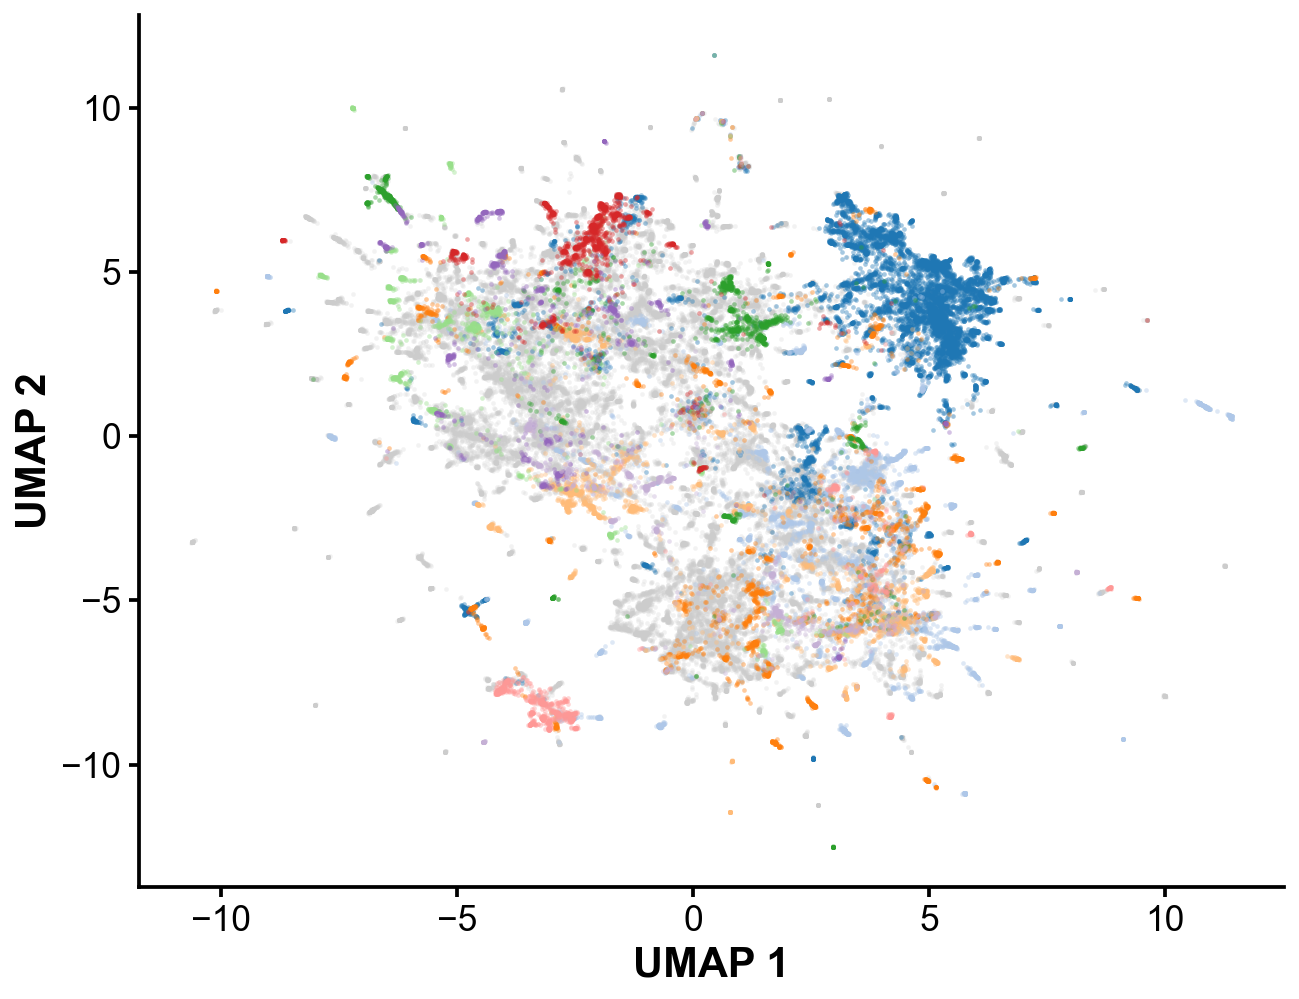

Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_subfield.{pdf,jpg,tiff}
Legend → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_subfield_legend.{pdf,jpg,tiff}


In [9]:
df_ok['subfield_clean'] = df_ok['subfield'].fillna('').astype(str).str.strip()
subfield_col, subfield_cmap = build_color_map(df_ok['subfield_clean'], TOP_SUBFIELDS)
df_ok['subfield_col'] = subfield_col

_title_sub = f'OpenAlex Subfield  (top {TOP_SUBFIELDS} shown)'
fig, ax = plt.subplots(figsize=(9, 7))
handles = scatter_umap(ax, df_ok, 'subfield_col', subfield_cmap, title=_title_sub)
plt.tight_layout()
_save_fig(fig, 'umap_corpus_subfield')
_save_legend_fig(handles, _title_sub, 'umap_corpus_subfield', ncol=2)
plt.show()
print(f'Saved → {OUTPUT_DIR}/umap_corpus_subfield.{{pdf,jpg,tiff}}')
print(f'Legend → {OUTPUT_DIR}/umap_corpus_subfield_legend.{{pdf,jpg,tiff}}')

## Cell 9 — Figure C: Corpus by Section

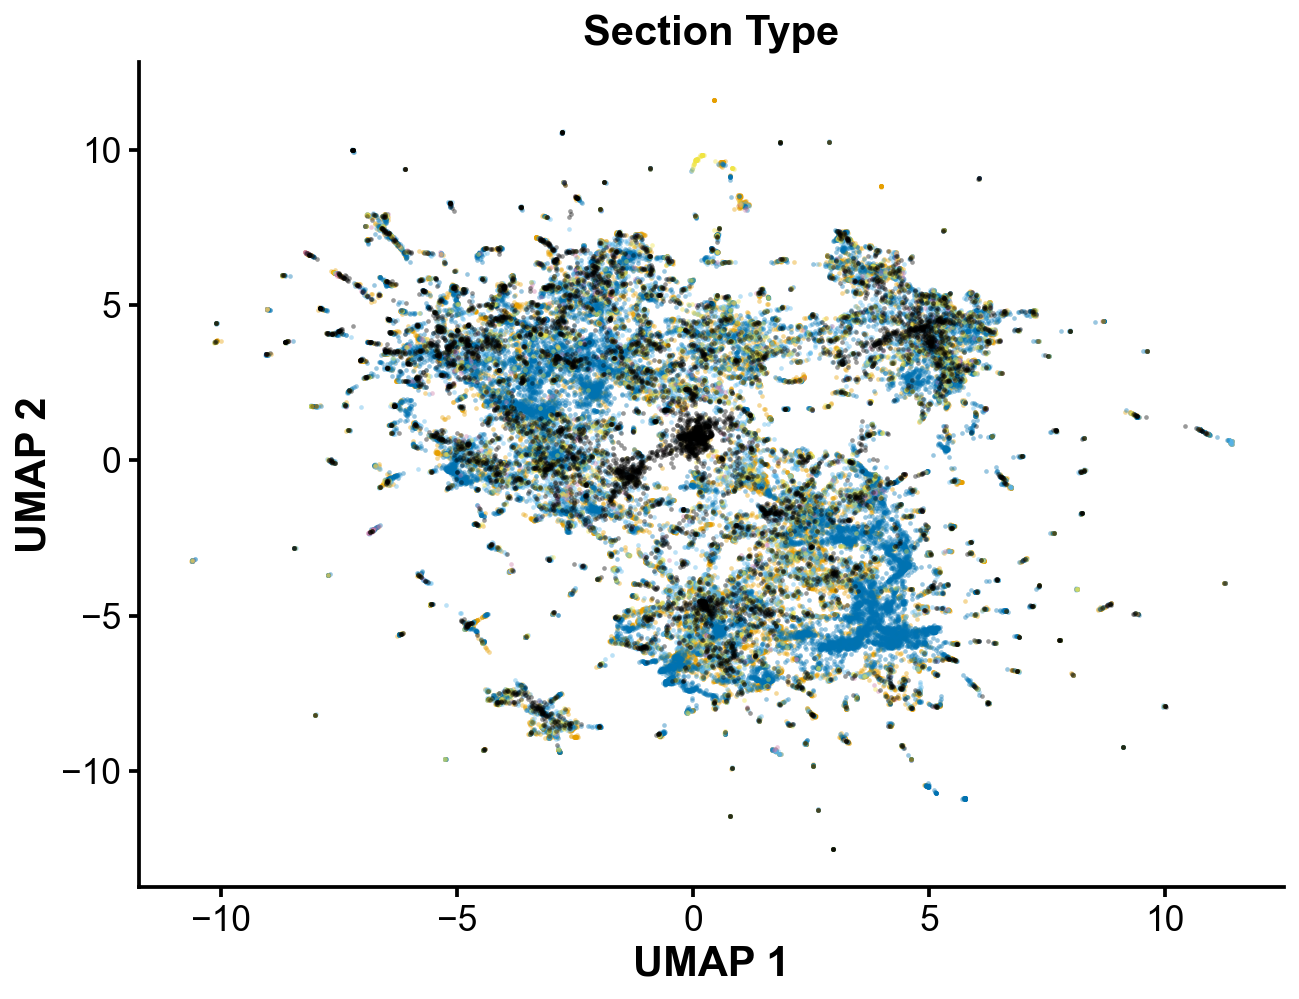

Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_section.{pdf,jpg,tiff}
Legend → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_section_legend.{pdf,jpg,tiff}
{'Results': 19886, 'Methods': 16811, 'Discussion': 16268, 'Introduction': 7932, 'Abstract': 3499, 'Conclusion': 1281}


In [10]:
# Colour-blind-safe section palette (Okabe–Ito derived). Previously Results=crimson
# (red) and Methods=emerald (green) appeared together in this same chart — reviewer
# feedback flagged red/green pairing as both inaccessible to common color vision
# deficiencies and carrying an unintended "red=bad / green=good" connotation.
_SEC_CMAP = {
    'Results'      : '#E69F00',   # orange
    'Discussion'   : '#56B4E9',   # sky blue
    'Methods'      : '#0072B2',   # deep blue
    'Conclusion'   : '#CC79A7',   # reddish-purple
    'Abstract'     : '#F0E442',   # yellow
    'Introduction' : '#000000',   # black
    'Other'        : '#CCCCCC',
}

def _norm_sec(s):
    s = str(s or '').strip().lower()
    if s in ('results', 'result'):                return 'Results'
    if s in ('discussion', 'discussions'):        return 'Discussion'
    if s in ('methods', 'method', 'methodology'): return 'Methods'
    if s in ('conclusion', 'conclusions'):        return 'Conclusion'
    if s == 'abstract':                           return 'Abstract'
    if s == 'introduction':                       return 'Introduction'
    return 'Other'

df_ok['section_norm'] = df_ok['section'].apply(_norm_sec)
_sec_counts = df_ok['section_norm'].value_counts()

fig, ax = plt.subplots(figsize=(9, 7))
for label, color in _SEC_CMAP.items():
    _sub = df_ok[df_ok['section_norm'] == label]
    if len(_sub) == 0:
        continue
    _alpha = 0.20 if label == 'Other' else PT_ALPHA
    _sz    = PT_SIZE * 0.8 if label == 'Other' else PT_SIZE
    ax.scatter(
        _sub['umap_x'], _sub['umap_y'],
        c=color, s=_sz, alpha=_alpha,
        linewidths=0, rasterized=False,
    )

ax.set_xlabel('UMAP 1', labelpad=4)
ax.set_ylabel('UMAP 2', labelpad=4)
ax.set_title('Section Type', fontweight='bold', pad=8)
plt.tight_layout()
_save_fig(fig, 'umap_corpus_section')
plt.show()

# Legend saved separately
_sec_handles = [
    mpatches.Patch(color=color, label=f'{lbl}  (n={_sec_counts.get(lbl, 0):,})')
    for lbl, color in _SEC_CMAP.items()
    if _sec_counts.get(lbl, 0) > 0
]
_save_legend_fig(_sec_handles, 'Section', 'umap_corpus_section', ncol=4)
print(f'Saved → {OUTPUT_DIR}/umap_corpus_section.{{pdf,jpg,tiff}}')
print(f'Legend → {OUTPUT_DIR}/umap_corpus_section_legend.{{pdf,jpg,tiff}}')
print(dict(_sec_counts))

## Cell 10 — Figure D: INCLUDE vs Non-INCLUDE

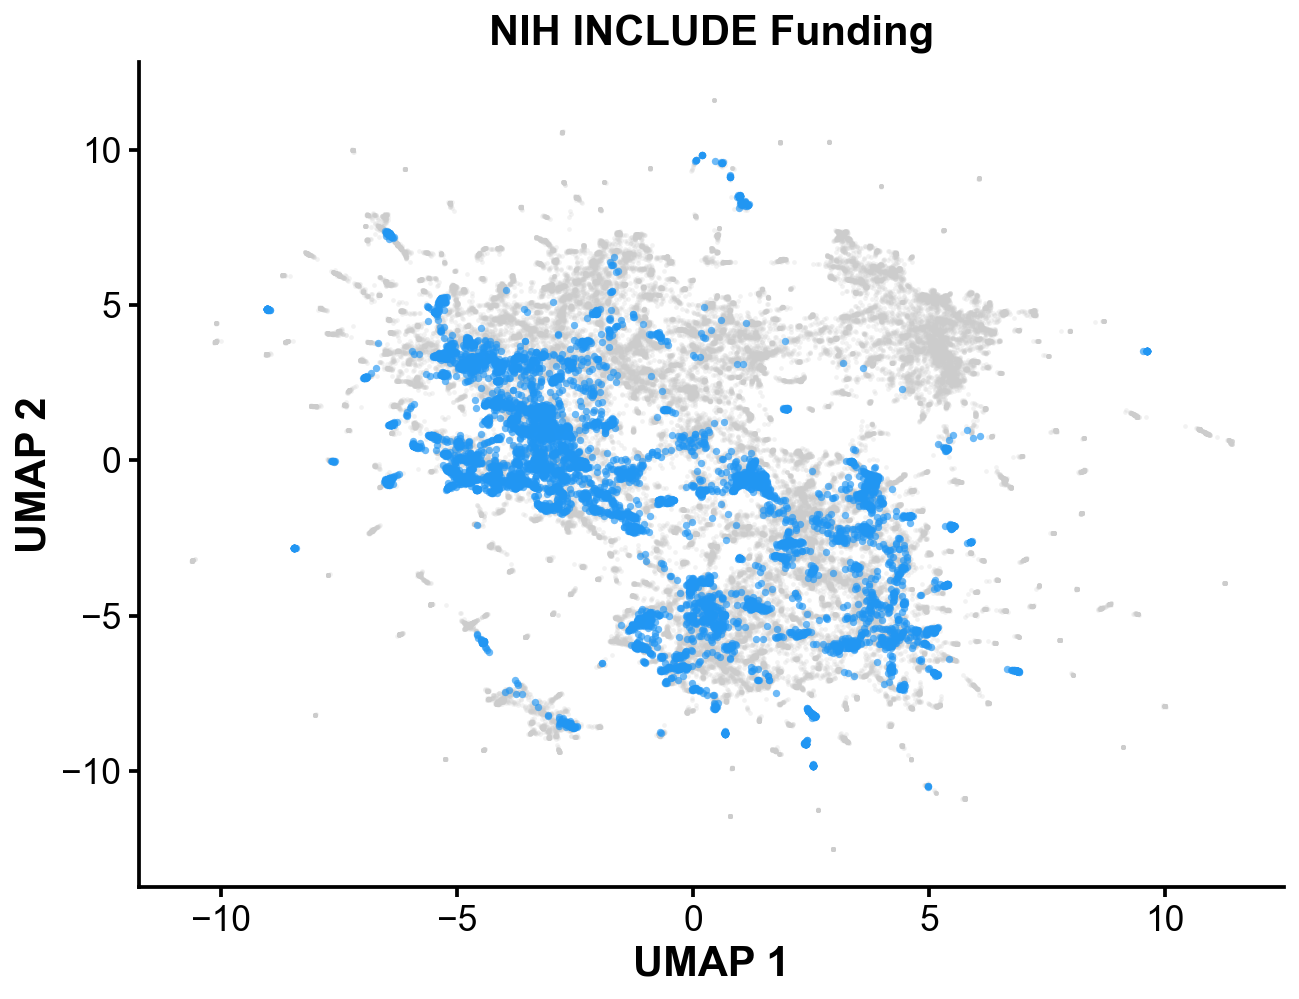

Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_include.{pdf,jpg,tiff}
Legend → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_include_legend.{pdf,jpg,tiff}


In [11]:
n_inc  = int((df_ok['is_include'] == 1).sum())
n_non  = len(df_ok) - n_inc

fig, ax = plt.subplots(figsize=(9, 7))

# Non-INCLUDE first (background)
_non = df_ok[df_ok['is_include'] != 1]
ax.scatter(
    _non['umap_x'], _non['umap_y'],
    c='#CCCCCC', s=PT_SIZE, alpha=0.25,
    linewidths=0, rasterized=False,
)

# INCLUDE on top
_inc = df_ok[df_ok['is_include'] == 1]
ax.scatter(
    _inc['umap_x'], _inc['umap_y'],
    c='#2196F3', s=PT_SIZE * 2.5, alpha=0.65,
    linewidths=0, rasterized=False,
)

ax.set_xlabel('UMAP 1', labelpad=4)
ax.set_ylabel('UMAP 2', labelpad=4)
ax.set_title('NIH INCLUDE Funding', fontweight='bold', pad=8)
plt.tight_layout()
_save_fig(fig, 'umap_corpus_include')
plt.show()

# Legend saved separately
_inc_handles = [
    mpatches.Patch(color='#CCCCCC', label=f'Non-INCLUDE  (n={n_non:,})'),
    mpatches.Patch(color='#2196F3', label=f'NIH INCLUDE  (n={n_inc:,})'),
]
_save_legend_fig(_inc_handles, 'Funding', 'umap_corpus_include', ncol=2)
print(f'Saved → {OUTPUT_DIR}/umap_corpus_include.{{pdf,jpg,tiff}}')
print(f'Legend → {OUTPUT_DIR}/umap_corpus_include_legend.{{pdf,jpg,tiff}}')

## Cell 11 — Save Coordinates + Metadata to CSV

In [12]:
cols_out = ['pmcid', 'section', 'topic', 'subfield', 'pub_field', 'domain',
            'is_include', 'umap_x', 'umap_y']
csv_path = OUTPUT_DIR / 'umap_corpus_coords.csv'
df_ok[cols_out].to_csv(csv_path, index=False)
print(f'Saved → {csv_path}  ({len(df_ok):,} rows)')

Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/umap_topic/umap_corpus_coords.csv  (65,677 rows)
